# Day-ahead hourly demand forecasting for a bike-sharing system

Capital Bikeshare (Washington D.C.) hourly rental counts for 2011 and 2012 are used to forecast the number of rentals in each hour of the following day. An operator uses such a forecast to position bikes and schedule rebalancing crews before the day starts.

The hosted copy is the UCI *Bike Sharing Dataset* (hourly file) with the `casual` and `registered` columns removed; in the original file their sum equals the target `cnt`, so keeping them would leak it.

## 1. Problem definition and metric

The forecast is issued the day before, so the legitimate inputs are calendar variables and a weather forecast; lagged demand is excluded. Observed weather stands in for the forecast, which understates the error a real deployment would see.

The primary metric is the mean absolute error (MAE) in bikes per hour: a misallocated bike costs roughly the same whether it is missing or idle (a repositioning trip or a lost ride), so a linear loss matches the operational cost and is read directly in bikes. WAPE (sum of absolute errors divided by total demand) expresses the same quantity as a share of volume; RMSE and RMSLE are reported as secondary views.

In [1]:
# Install only what is missing (Colab already ships all of these)
import importlib.util, subprocess, sys

REQUIRED = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, SplineTransformer, StandardScaler

warnings.simplefilter("ignore")  # keeps library deprecation notices out of the output
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

python 3.13.16 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 2. Data import and quality audit

The file is read from the public repository copy; a local `bike.csv` takes precedence when present (for offline use).

In [3]:
URL = "https://raw.githubusercontent.com/pycaret/pycaret/master/datasets/bike.csv"
LOCAL = "bike.csv"
raw = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)

df = raw.copy()
df["date"] = pd.to_datetime(df["dteday"], format="%m/%d/%Y")
# The file stores weather scaled to [0, 1]; the documented maxima restore physical units
df["temp"] *= 41
df["atemp"] *= 50
df["hum"] *= 100
df["windspeed"] *= 67

print(f"{df.shape[0]:,} rows x {raw.shape[1]} columns, {df['date'].min().date()} to {df['date'].max().date()}")
print("non-numeric columns in the raw file:", [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])])

17,379 rows x 15 columns, 2011-01-01 to 2012-12-31
non-numeric columns in the raw file: ['dteday']


Every check below is run before any modelling; the decision column records how each finding is handled.

In [4]:
all_hours = pd.MultiIndex.from_product([df["date"].unique(), range(24)])
absent = all_hours.difference(pd.MultiIndex.from_frame(df[["date", "hr"]]))
night_share = np.mean([h <= 5 for _, h in absent])

g = df.groupby(["hr", "workingday"])["cnt"]
q1, q3 = g.transform(lambda s: s.quantile(0.25)), g.transform(lambda s: s.quantile(0.75))
n_outliers = int((df["cnt"] > q3 + 3 * (q3 - q1)).sum())

hum0_days = df.loc[df["hum"] == 0, "date"].dt.date.unique()
consistent = (
    (df["date"].dt.dayofweek.add(1) % 7 == df["weekday"]).all()
    and (df["date"].dt.month == df["mnth"]).all()
    and (df["date"].dt.year - 2011 == df["yr"]).all()
    and ((df["weekday"].isin([0, 6]) | (df["holiday"] == 1)) == (df["workingday"] == 0)).all()
)
corr_t = df["temp"].corr(df["atemp"])

rows = [
    ("Types", "`dteday` is text (month/day/year); all other columns numeric; weather stored scaled to [0, 1]",
     "Date parsed; weather rescaled to physical units"),
    ("Duplicates", f"{int(raw.duplicated().sum())} duplicated rows, {int(df.duplicated(['date', 'hr']).sum())} duplicated (date, hour) keys",
     "None to remove; no duplicate groups, so groups for validation come from time adjacency instead"),
    ("Missing values", f"{int(raw.isna().sum().sum())} empty cells, but {len(absent)} of {len(all_hours):,} (date, hour) slots are absent ({night_share:.0%} between 00:00 and 05:59)",
     "Absent slots are hours with zero rentals (minimum observed count is %d); the model forecasts demand for hours that have at least one rental" % df["cnt"].min()),
    ("Impossible values", f"humidity = 0 in {int((df['hum'] == 0).sum())} rows, all on {', '.join(map(str, hum0_days))}",
     "Set to missing; imputed inside each pipeline (native missing-value support for boosting)"),
    ("Suspicious zeros", f"windspeed = 0 in {int((df['windspeed'] == 0).sum())} rows ({(df['windspeed'] == 0).mean():.1%}); no readings between 0 and the next level",
     "Kept: zero marks 'below sensor resolution', a legitimate level"),
    ("Outliers", f"{n_outliers} rows exceed Q3 + 3 IQR within their (hour, day type) group",
     "Kept: genuine peak demand, which is exactly what must be forecast; MAE is robust to them"),
    ("Redundancy", f"calendar fields consistent with the date: {bool(consistent)}; temp vs atemp correlation {corr_t:.3f}; `season` is a coarser re-labelling of month",
     "`season` and `instant` (row counter) dropped; temp and atemp kept (trees are indifferent, ridge regularises)"),
    ("Leakage", "`casual` and `registered` absent; all remaining inputs are known the day before (calendar) or forecastable (weather)",
     "No target-derived column; no lagged demand is built"),
]
display(pd.DataFrame(rows, columns=["Check", "Finding", "Decision"]))

,Check,Finding,Decision
0,Types,"`dteday` is text (month/day/year); all other columns numeric; weather stored scaled to [0, 1]",Date parsed; weather rescaled to physical units
1,Duplicates,"0 duplicated rows, 0 duplicated (date, hour) keys","None to remove; no duplicate groups, so groups for validation come from time adjacency instead"
2,Missing values,"0 empty cells, but 165 of 17,544 (date, hour) slots are absent (67% between 00:00 and 05:59)",Absent slots are hours with zero rentals (minimum observed count is 1); the model forecasts demand for hours that have at least one rental
3,Impossible values,"humidity = 0 in 22 rows, all on 2011-03-10",Set to missing; imputed inside each pipeline (native missing-value support for boosting)
4,Suspicious zeros,windspeed = 0 in 2180 rows (12.5%); no readings between 0 and the next level,"Kept: zero marks 'below sensor resolution', a legitimate level"
5,Outliers,"23 rows exceed Q3 + 3 IQR within their (hour, day type) group","Kept: genuine peak demand, which is exactly what must be forecast; MAE is robust to them"
6,Redundancy,calendar fields consistent with the date: True; temp vs atemp correlation 0.988; `season` is a coarser re-labelling of month,"`season` and `instant` (row counter) dropped; temp and atemp kept (trees are indifferent, ridge regularises)"
7,Leakage,`casual` and `registered` absent; all remaining inputs are known the day before (calendar) or forecastable (weather),No target-derived column; no lagged demand is built


In [5]:
df.loc[df["hum"] == 0, "hum"] = np.nan
df["day"] = (df["date"] - df["date"].min()).dt.days   # days since 2011-01-01, used only for diagnostics and one ablation
data = df.drop(columns=["instant", "dteday", "season"])

## 3. Validation design

The last quarter of 2012 is held out chronologically and is evaluated exactly once, at the end. Everything else (model choice, ablation, tuning) uses repeated 5-fold cross-validation in which whole weeks are the grouping unit, because neighbouring hours share weather and demand level and a row-wise split would let near-copies of a validation hour sit in the training folds.

In [6]:
HOLDOUT_START = pd.Timestamp("2012-10-01")
is_hold = data["date"] >= HOLDOUT_START
train = data[~is_hold].reset_index(drop=True)
hold = data[is_hold].reset_index(drop=True)   # not referenced again until section 11

N_SPLITS = 5
week = (train["day"] // 7).to_numpy()

def make_folds(seed):
    """Shuffled grouped K-fold: weeks are permuted per seed and dealt round-robin into folds."""
    weeks = np.random.RandomState(seed).permutation(np.unique(week))
    fold_of = dict(zip(weeks, np.arange(len(weeks)) % N_SPLITS))
    fold = np.array([fold_of[w] for w in week])
    return [(np.where(fold != k)[0], np.where(fold == k)[0]) for k in range(N_SPLITS)]

sizes = [len(v) for _, v in make_folds(0)]
print(f"train {len(train):,} rows ({train['date'].min().date()} to {train['date'].max().date()}), "
      f"hold-out {len(hold):,} rows ({hold['date'].min().date()} to {hold['date'].max().date()})")
print(f"{len(np.unique(week))} weekly groups, validation fold sizes {min(sizes)} to {max(sizes)} rows")

train 15,211 rows (2011-01-01 to 2012-09-30), hold-out 2,168 rows (2012-10-01 to 2012-12-31)
92 weekly groups, validation fold sizes 2899 to 3159 rows


## 4. Exploration (training period only)

mean hourly demand January-September: 2011 144.4, 2012 239.8 (+66.1%)


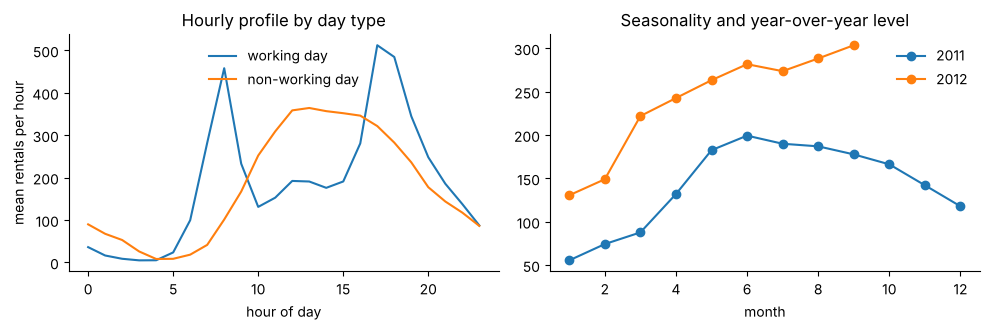

In [7]:
sub = train[train["mnth"] <= 9]   # same months in both years; hold-out period excluded from exploration
yearly = sub.groupby("yr")["cnt"].mean()
print(f"mean hourly demand January-September: 2011 {yearly[0]:.1f}, 2012 {yearly[1]:.1f} ({yearly[1] / yearly[0] - 1:+.1%})")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for wd, label in [(1, "working day"), (0, "non-working day")]:
    ax[0].plot(train[train["workingday"] == wd].groupby("hr")["cnt"].mean(), label=label)
ax[0].set(xlabel="hour of day", ylabel="mean rentals per hour", title="Hourly profile by day type")
ax[0].legend(frameon=False, loc="upper center")
for yr, label in [(0, "2011"), (1, "2012")]:
    ax[1].plot(train[train["yr"] == yr].groupby("mnth")["cnt"].mean(), marker="o", label=label)
ax[1].set(xlabel="month", title="Seasonality and year-over-year level")
ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()

Working days show commute peaks around 08:00 and 17:00 to 18:00, non-working days a broad midday hump, so hour and day type interact and are crossed explicitly in the linear model. For January to September, mean hourly demand rises from 144.4 in 2011 to 239.8 in 2012 (+66.1%), a level shift that makes the year flag powerful and its extrapolation a risk.

Three input groups are defined for the ablation. The trend group holds only the binary year flag, since a continuous time index cannot be extrapolated by tree models.

In [8]:
GROUPS = {
    "calendar": ["hr", "weekday", "workingday", "holiday", "mnth"],
    "weather": ["temp", "atemp", "hum", "windspeed", "weathersit"],
    "trend": ["yr"],
}
FEATURES = [c for cols in GROUPS.values() for c in cols]
X_train, y_train = train[FEATURES + ["day"]], train["cnt"]


def metrics(y_true, y_pred):
    err = y_pred - y_true
    return {
        "MAE": np.abs(err).mean(),
        "WAPE": np.abs(err).sum() / y_true.sum(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "RMSLE": np.sqrt(((np.log1p(y_pred) - np.log1p(y_true)) ** 2).mean()),
    }


def cv(model, cols, seeds, X=X_train, y=y_train):
    """Per-fold metrics over repeated grouped CV; predictions are clipped at zero (counts)."""
    rows = []
    for s in seeds:
        for k, (a, v) in enumerate(make_folds(s)):
            fitted = clone(model).fit(X.iloc[a][cols], y.iloc[a])
            pred = np.clip(fitted.predict(X.iloc[v][cols]), 0, None)
            rows.append({"seed": s, "fold": k, **metrics(y.iloc[v].to_numpy(), pred)})
    return pd.DataFrame(rows)


def oof_predictions(model, cols, seed, X=X_train, y=y_train):
    pred = np.zeros(len(y))
    for a, v in make_folds(seed):
        pred[v] = np.clip(clone(model).fit(X.iloc[a][cols], y.iloc[a]).predict(X.iloc[v][cols]), 0, None)
    return pred

## 5. Model comparison

The ladder runs from trivial references (global median; median per hour and day type) through an interpretable regularised linear model to bagged trees and gradient boosting. Preprocessing that learns from data (imputation, scaling, spline knots, ridge penalty) sits inside each pipeline, so it is refitted on every training fold.

In [9]:
class ProfileBaseline(BaseEstimator, RegressorMixin):
    """Median demand per (hour, working-day flag): the strongest rule that needs no model."""
    def fit(self, X, y):
        self.table_ = y.groupby([X["hr"].to_numpy(), X["workingday"].to_numpy()]).median()
        self.default_ = y.median()
        return self

    def predict(self, X):
        keys = pd.MultiIndex.from_arrays([X["hr"].to_numpy(), X["workingday"].to_numpy()])
        return self.table_.reindex(keys).fillna(self.default_).to_numpy()


def add_hour_daytype(X):
    return X.assign(hr_wd=X["hr"] * 2 + X["workingday"])   # separate hourly profile for working / non-working days


def ridge_pipeline():
    prep = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="ignore"), ["hr_wd", "weekday", "mnth", "weathersit"]),
        ("weather", make_pipeline(SimpleImputer(strategy="median"), SplineTransformer(n_knots=5), StandardScaler()),
         ["temp", "atemp", "hum", "windspeed"]),
        ("flags", "passthrough", ["yr", "holiday"]),
    ])
    return make_pipeline(FunctionTransformer(add_hour_daytype), prep, RidgeCV(alphas=np.logspace(-2, 3, 12)))


def hgb(**params):
    base = dict(loss="poisson", learning_rate=0.08, max_iter=300, early_stopping=False, random_state=SEED)
    return HistGradientBoostingRegressor(**{**base, **params})


def with_imputer(model):
    return make_pipeline(SimpleImputer(strategy="median"), model)


MODELS = {
    "Median (global)": DummyRegressor(strategy="median"),
    "Median by hour x day type": ProfileBaseline(),
    "Ridge, raw target": ridge_pipeline(),
    "Ridge, log1p target": TransformedTargetRegressor(ridge_pipeline(), func=np.log1p, inverse_func=np.expm1),
    "Random forest": with_imputer(RandomForestRegressor(150, min_samples_leaf=3, max_features=0.6, n_jobs=-1, random_state=SEED)),
    "Extra trees": with_imputer(ExtraTreesRegressor(150, min_samples_leaf=2, max_features=0.8, n_jobs=-1, random_state=SEED)),
    "HGB, squared error": hgb(loss="squared_error"),
    "HGB, absolute error": hgb(loss="absolute_error"),
    "HGB, Poisson": hgb(),
}
CV_SEEDS = [0, 1, 2]
scores = {name: cv(model, FEATURES, CV_SEEDS) for name, model in MODELS.items()}

def summarise(table):
    out = pd.DataFrame({
        n: {"MAE": s["MAE"].mean(), "MAE fold sd": s["MAE"].std(), "WAPE %": 100 * s["WAPE"].mean(),
            "RMSE": s["RMSE"].mean(), "RMSLE": s["RMSLE"].mean()} for n, s in table.items()}).T
    return out.round({"MAE": 2, "MAE fold sd": 2, "WAPE %": 1, "RMSE": 2, "RMSLE": 3})

display(summarise(scores))

,MAE,MAE fold sd,WAPE %,RMSE,RMSLE
Median (global),135.07,9.69,73.1,183.83,1.470
Median by hour x day type,72.58,6.74,39.6,109.42,0.641
"Ridge, raw target",49.70,4.17,26.9,71.48,1.092
"Ridge, log1p target",35.36,3.17,19.1,57.80,0.369
Random forest,32.14,2.33,17.4,50.58,0.409
Extra trees,30.98,2.28,16.8,48.86,0.422
"HGB, squared error",27.88,2.19,15.1,44.83,0.479
"HGB, absolute error",27.06,2.35,14.7,43.93,0.389
"HGB, Poisson",26.80,2.19,14.5,44.41,0.347


The hour x day-type median roughly halves the global-median error; the log-target ridge (35.36 against 72.58 for the profile) and Poisson boosting (26.80) cut it further. The log target matters for ridge (49.70 with the raw target) because demand scales multiplicatively with hour, season and year, and the Poisson loss gives boosting the same multiplicative structure.

## 6. Noise floor and paired comparisons

All models are scored on identical folds, so the per-fold difference between two models is a paired quantity. A gain counts as an improvement only when it exceeds twice its standard error and the challenger wins in at least 80% of the folds; the folds overlap in their training data, so the standard error is approximate and on the optimistic side.

In [10]:
def paired(ref_scores, alt_scores, metric="MAE"):
    gain = ref_scores[metric].to_numpy() - alt_scores[metric].to_numpy()   # positive: challenger better
    se = gain.std(ddof=1) / np.sqrt(len(gain))
    win = (gain > 0).mean()
    verdict = "improvement" if gain.mean() > 2 * se and win >= 0.8 else ("worse" if gain.mean() < -2 * se and win <= 0.2 else "within noise")
    return {"MAE gain": round(gain.mean(), 2), "SE": round(se, 2), "folds won": f"{win:.0%}", "verdict": verdict}

PAIRS = [
    ("Median by hour x day type", "Ridge, log1p target"),
    ("Ridge, raw target", "Ridge, log1p target"),
    ("Ridge, log1p target", "Extra trees"),
    ("Random forest", "Extra trees"),
    ("Extra trees", "HGB, Poisson"),
    ("HGB, squared error", "HGB, Poisson"),
    ("HGB, absolute error", "HGB, Poisson"),
]
table = pd.DataFrame([{"reference": r, "challenger": c, **paired(scores[r], scores[c])} for r, c in PAIRS])
display(table)

,reference,challenger,MAE gain,SE,folds won,verdict
0,Median by hour x day type,"Ridge, log1p target",37.23,1.86,100%,improvement
1,"Ridge, raw target","Ridge, log1p target",14.35,0.65,100%,improvement
2,"Ridge, log1p target",Extra trees,4.38,0.49,100%,improvement
3,Random forest,Extra trees,1.16,0.13,100%,improvement
4,Extra trees,"HGB, Poisson",4.17,0.26,100%,improvement
5,"HGB, squared error","HGB, Poisson",1.07,0.15,100%,improvement
6,"HGB, absolute error","HGB, Poisson",0.25,0.15,60%,within noise


The fold-to-fold standard deviation of MAE is 2.19 to 2.35 for the tree models, larger than most gaps in the previous table, so raw differences alone are not evidence. Paired on identical folds, Poisson boosting beats extra trees by 4.17 (SE 0.26) and squared-error boosting by 1.07 (SE 0.15), whereas absolute versus Poisson loss (0.25, 60% of folds) stays within noise. The Poisson objective is kept because it encodes the multiplicative structure, not because it won against the absolute-error objective.

## 7. Ablation of input groups

Gradient boosting with the Poisson loss is refitted with one group removed at a time, and with each group alone, on the first two CV repeats (the reference row reuses the same folds). Replacing the year flag by a continuous day counter is included because it changes how the model handles growth.

In [11]:
ABL_SEEDS = [0, 1]
ref = scores["HGB, Poisson"][scores["HGB, Poisson"]["seed"].isin(ABL_SEEDS)].reset_index(drop=True)
cal, wea, trd = GROUPS["calendar"], GROUPS["weather"], GROUPS["trend"]
VARIANTS = {
    "without trend": cal + wea,
    "without weather": cal + trd,
    "without calendar": wea + trd,
    "calendar only": cal,
    "without month": [c for c in FEATURES if c != "mnth"],
    "without holiday, windspeed, atemp": [c for c in FEATURES if c not in ("holiday", "windspeed", "atemp")],
    "day counter instead of year flag": cal + wea + ["day"],
}
rows = [{"variant": "all groups (reference)", "MAE": round(ref["MAE"].mean(), 2), "MAE increase": 0.0, "SE": np.nan, "folds worse": ""}]
for name, cols in VARIANTS.items():
    s = cv(hgb(), cols, ABL_SEEDS)
    delta = s["MAE"].to_numpy() - ref["MAE"].to_numpy()
    rows.append({"variant": name, "MAE": round(s["MAE"].mean(), 2), "MAE increase": round(delta.mean(), 2),
                 "SE": round(delta.std(ddof=1) / np.sqrt(len(delta)), 2), "folds worse": f"{(delta > 0).mean():.0%}"})
display(pd.DataFrame(rows))

,variant,MAE,MAE increase,SE,folds worse
0,all groups (reference),26.64,0.00,NaN,
1,without trend,49.82,23.18,1.04,100%
2,without weather,37.80,11.16,0.87,100%
3,without calendar,108.81,82.18,2.55,100%
4,calendar only,62.11,35.47,1.25,100%
5,without month,29.89,3.25,0.40,100%
6,"without holiday, windspeed, atemp",26.86,0.22,0.13,80%
7,day counter instead of year flag,25.77,-0.87,0.44,20%


Removing the calendar group costs the most (+82.18 MAE), followed by trend (+23.18) and weather (+11.16), so every group carries signal. Dropping holiday, windspeed and atemp, the three weakest inputs in section 10, costs 0.22 (SE 0.13) and is not an improvement, so the full set is retained. The day counter looks better by 0.87 (SE 0.44) in these folds, which interpolate between weeks that bracket every validation week.

Random K-fold interpolates between weeks that bracket every validation week, so it cannot judge how a trend encoding behaves on future data. A forward check inside the training period (fit up to June 2012, predict July to September 2012) settles the encoding without touching the hold-out.

In [12]:
fit_part = train["date"] < "2012-07-01"
rows = []
for name, cols in [("year flag", FEATURES), ("day counter", [c for c in FEATURES if c != "yr"] + ["day"])]:
    m = hgb().fit(train.loc[fit_part, cols], y_train[fit_part])
    pred = np.clip(m.predict(train.loc[~fit_part, cols]), 0, None)
    rows.append({"trend encoding": name, "forward MAE (Jul-Sep 2012)": round(metrics(y_train[~fit_part].to_numpy(), pred)["MAE"], 2)})
display(pd.DataFrame(rows))

,trend encoding,forward MAE (Jul-Sep 2012)
0,year flag,38.28
1,day counter,42.12


On later data the year flag wins (38.28 against 42.12), reversing the cross-validation ranking, because trees cannot extrapolate beyond the largest counter value seen in training. The year flag is therefore kept. The forward error also exceeds the 26.80 of grouped CV, which signals a gap on the hold-out.

## 8. Budget-capped hyper-parameter search

Random search over the boosting parameters is limited to 14 candidates scored on one fresh repeat of the 5 folds (70 fits), against a full grid of several hundred. Any gain found this way is suspect until it survives on folds that played no part in the selection.

In [13]:
SPACE = {
    "learning_rate": [0.03, 0.05, 0.08, 0.12],
    "max_iter": [200, 400, 600],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [5, 10, 20, 40],
    "l2_regularization": [0.0, 0.1, 1.0, 10.0],
}
N_ITER, SEARCH_SEED = 14, 10
rng = np.random.RandomState(SEED)
candidates = [{k: rng.choice(v).item() for k, v in SPACE.items()} for _ in range(N_ITER)]
mae_by_candidate = [cv(hgb(**p), FEATURES, [SEARCH_SEED])["MAE"].mean() for p in candidates]
ranked = [(candidates[i], mae_by_candidate[i]) for i in np.argsort(mae_by_candidate)]
search = pd.DataFrame([{**p, "MAE": m} for p, m in ranked])
display(search.head(5).round({"MAE": 2}))

,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,MAE
0,0.03,400,31,10,0.0,27.08
1,0.05,200,31,40,10.0,27.22
2,0.08,600,31,40,10.0,27.22
3,0.08,200,63,20,10.0,27.24
4,0.12,200,15,40,0.1,27.32


Finalists are re-scored on three CV repeats with seeds never used before. The gap between the selection-time and fresh score exposes the optimism of picking the best of 14. A tuned configuration replaces the untuned reference only if it passes the improvement rule of section 6 on these fresh folds.

In [14]:
FRESH_SEEDS = [100, 101, 102]
tuned = {f"HGB tuned #{i + 1}": hgb(**ranked[i][0]) for i in range(3)}
finalists = {"HGB, Poisson (reference)": hgb(), "Extra trees": MODELS["Extra trees"],
             "Ridge, log1p target": MODELS["Ridge, log1p target"], **tuned}
selection_mae = {"HGB, Poisson (reference)": scores["HGB, Poisson"]["MAE"].mean(),
                 "Extra trees": scores["Extra trees"]["MAE"].mean(),
                 "Ridge, log1p target": scores["Ridge, log1p target"]["MAE"].mean(),
                 **{f"HGB tuned #{i + 1}": ranked[i][1] for i in range(3)}}
fresh = {n: cv(m, FEATURES, FRESH_SEEDS) for n, m in finalists.items()}

out = summarise(fresh)[["MAE", "MAE fold sd", "WAPE %"]].rename(columns={"MAE": "fresh-fold MAE"})
out.insert(0, "selection-time MAE", pd.Series(selection_mae).round(2))
display(out)

REF = "HGB, Poisson (reference)"
verdicts = pd.DataFrame([{"challenger": n, **paired(fresh[REF], fresh[n])} for n in tuned])
display(verdicts)

chosen_name = REF
best_gain = 0.0
for _, r in verdicts.iterrows():
    if r["verdict"] == "improvement" and r["MAE gain"] > best_gain:
        chosen_name, best_gain = r["challenger"], r["MAE gain"]
final_model = finalists[chosen_name]
print("selected for the hold-out:", chosen_name)

,selection-time MAE,fresh-fold MAE,MAE fold sd,WAPE %
"HGB, Poisson (reference)",26.80,26.99,1.89,14.6
Extra trees,30.98,31.15,2.55,16.9
"Ridge, log1p target",35.36,35.44,3.44,19.2
HGB tuned #1,27.08,27.25,2.07,14.7
HGB tuned #2,27.22,27.40,2.19,14.8
HGB tuned #3,27.22,27.20,1.89,14.7


,challenger,MAE gain,SE,folds won,verdict
0,HGB tuned #1,-0.25,0.11,27%,within noise
1,HGB tuned #2,-0.41,0.14,7%,worse
2,HGB tuned #3,-0.21,0.06,13%,worse


selected for the hold-out: HGB, Poisson (reference)


No tuned configuration beats the untuned reference on fresh folds (gains of -0.25, -0.41 and -0.21 MAE). Selection-time scores sit 0.17 and 0.18 below fresh scores for the first two tuned models, but the reference shifts by a similar 0.19 without any selection, so the shift reflects the folds rather than selection optimism. The untuned boosting model is the best among the options tested, not a proven optimum.

## 9. Error analysis

Out-of-fold predictions of the selected model on the training period show where it fails, without involving the hold-out.

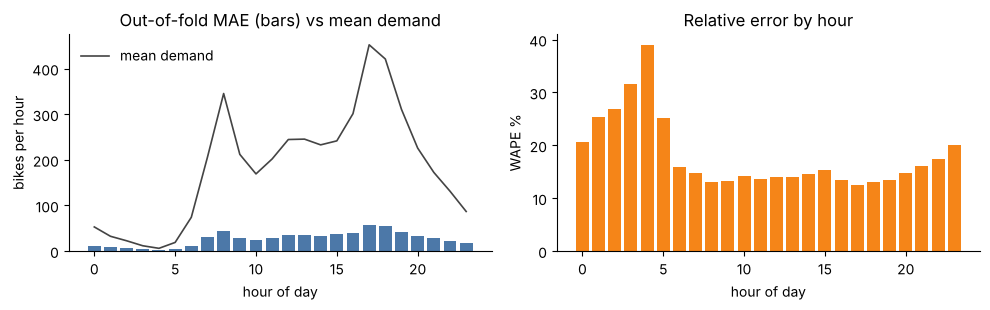

,rows,demand,MAE,WAPE %
weathersit,,,,
1,10189,201.0,24.98,12.4
2,3760,168.4,26.61,15.8
3,1259,108.4,41.59,38.4
4,3,74.3,17.31,23.3


,actual,predicted,abs_err
date,,,
2012-04-16,6370,5976,3383
2011-11-24,1495,3764,2270
2012-03-23,8362,6227,2172
2011-12-24,1011,3175,2164
2011-12-25,754,2883,2129


In [15]:
FINAL_COLS = FEATURES
oof = train[["date", "hr", "workingday", "weathersit", "cnt"]].assign(pred=oof_predictions(final_model, FINAL_COLS, seed=0))
oof["abs_err"] = (oof["pred"] - oof["cnt"]).abs()

by_hour = oof.groupby("hr").agg(demand=("cnt", "mean"), MAE=("abs_err", "mean"), err_sum=("abs_err", "sum"), cnt_sum=("cnt", "sum"))
by_hour["WAPE %"] = 100 * by_hour["err_sum"] / by_hour["cnt_sum"]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(by_hour.index, by_hour["MAE"], color="#4c78a8")
ax[0].plot(by_hour.index, by_hour["demand"], color="#444", lw=1.2, label="mean demand")
ax[0].set(xlabel="hour of day", ylabel="bikes per hour", title="Out-of-fold MAE (bars) vs mean demand")
ax[0].legend(frameon=False)
ax[1].bar(by_hour.index, by_hour["WAPE %"], color="#f58518")
ax[1].set(xlabel="hour of day", ylabel="WAPE %", title="Relative error by hour")
plt.tight_layout()
plt.show()

by_weather = oof.groupby("weathersit").agg(rows=("cnt", "size"), demand=("cnt", "mean"), MAE=("abs_err", "mean"),
                                           err_sum=("abs_err", "sum"), cnt_sum=("cnt", "sum"))
by_weather["WAPE %"] = 100 * by_weather["err_sum"] / by_weather["cnt_sum"]
display(by_weather.drop(columns=["err_sum", "cnt_sum"]).round({"demand": 1, "MAE": 2, "WAPE %": 1}))

days = oof.groupby("date").agg(actual=("cnt", "sum"), predicted=("pred", "sum"), abs_err=("abs_err", "sum"))
display(days.sort_values("abs_err", ascending=False).head(5).round(0).astype(int))

Absolute error follows demand, peaking at the commute hours, while relative error is highest overnight where volumes are small. Heavy-weather hours (weathersit 3) reach a WAPE of 38.4% against 12.4% in clear weather, on only 1,259 rows. Holiday-type days dominate the worst days: 2011-11-24 and the Christmas Eve and Day of 2011 (not flagged as holidays in the file) are over-predicted by roughly 2,100 to 2,300 rentals, since each such day appears once or twice in training and the model has almost nothing to learn their shape from.

## 10. Feature importance

Permutation importance on held-out folds (increase in MAE when one input is shuffled) is averaged over the five folds of one CV repeat.

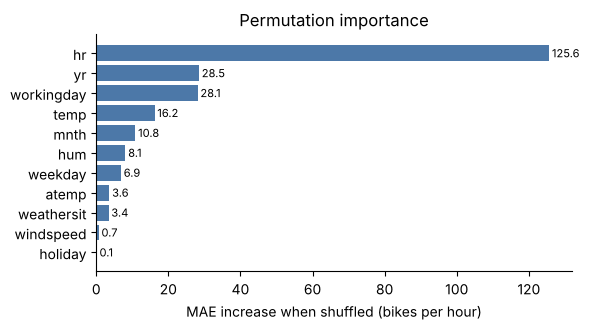

In [16]:
imp = []
for a, v in make_folds(0):
    m = clone(final_model).fit(X_train.iloc[a][FINAL_COLS], y_train.iloc[a])
    r = permutation_importance(m, X_train.iloc[v][FINAL_COLS], y_train.iloc[v], scoring="neg_mean_absolute_error",
                               n_repeats=3, random_state=SEED)
    imp.append(r.importances_mean)
importance = pd.Series(np.mean(imp, axis=0), index=FINAL_COLS).sort_values()

fig, ax = plt.subplots(figsize=(6, 3.4))
bars = ax.barh(importance.index, importance.values, color="#4c78a8")
ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
ax.set(xlabel="MAE increase when shuffled (bikes per hour)", title="Permutation importance")
plt.tight_layout()
plt.show()

Hour dominates (125.6 bikes of MAE when shuffled), followed by the year flag (28.5) and the working-day flag (28.1); holiday (0.1), windspeed (0.7) and atemp (3.6, largely redundant with temp at 16.2) contribute little. The weight of the year flag supports keeping the trend group, and the weak tail motivated the reduced-set test of section 7, where removal did not help. The near-zero holiday importance also matches the holiday failures of section 9.

## 11. Hold-out evaluation

The hold-out is scored once, in this single cell, for the selected model and three references fixed beforehand. All are refitted on the full training period; no decision follows. A 95% interval comes from resampling whole days.

,MAE,WAPE %,RMSE,RMSLE
model,,,,
Median by hour x day type,80.87,36.9,120.39,0.604
"Ridge, log1p target",47.05,21.5,75.83,0.460
"HGB, Poisson (reference) [selected]",44.12,20.1,70.30,0.417


selected model, 95% day-bootstrap interval: MAE 40.24 to 48.30 | WAPE 17.7% to 22.8%


,MAE,bias %
month,,
2012-10,39.8,-5.0
2012-11,42.5,-10.5
2012-12,49.8,-8.7


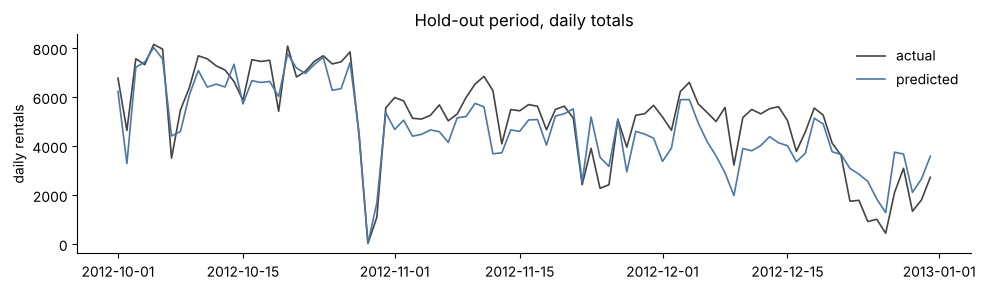

In [17]:
X_hold, y_hold = hold[FEATURES + ["day"]], hold["cnt"]
contenders = {
    "Median by hour x day type": ProfileBaseline(),
    "Ridge, log1p target": MODELS["Ridge, log1p target"],
    "HGB, Poisson (reference)": hgb(),
}
contenders[chosen_name] = final_model   # identical to the reference unless a tuned model passed the rule
preds, rows = {}, []
for name, model in contenders.items():
    preds[name] = np.clip(clone(model).fit(X_train[FEATURES], y_train).predict(X_hold[FEATURES]), 0, None)
    rows.append({"model": name + (" [selected]" if name == chosen_name else ""), **metrics(y_hold.to_numpy(), preds[name])})
result = pd.DataFrame(rows).set_index("model")
result["WAPE"] *= 100
display(result.rename(columns={"WAPE": "WAPE %"}).round({"MAE": 2, "WAPE %": 1, "RMSE": 2, "RMSLE": 3}))

# Day-level bootstrap of the selected model's MAE and WAPE
sel = chosen_name
daily = pd.DataFrame({"date": hold["date"], "err": (preds[sel] - y_hold).abs(), "cnt": y_hold}).groupby("date").agg(
    err=("err", "sum"), cnt=("cnt", "sum"), n=("err", "size"))
rs = np.random.RandomState(SEED)
boot = []
for _ in range(2000):
    s = daily.iloc[rs.randint(0, len(daily), len(daily))]
    boot.append((s["err"].sum() / s["n"].sum(), 100 * s["err"].sum() / s["cnt"].sum()))
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
print(f"selected model, 95% day-bootstrap interval: MAE {lo[0]:.2f} to {hi[0]:.2f} | WAPE {lo[1]:.1f}% to {hi[1]:.1f}%")

monthly = pd.DataFrame({"month": hold["date"].dt.strftime("%Y-%m"), "actual": y_hold, "predicted": preds[sel]}).assign(
    abs_err=lambda d: (d["predicted"] - d["actual"]).abs()).groupby("month").agg(
    MAE=("abs_err", "mean"), actual=("actual", "sum"), predicted=("predicted", "sum"))
monthly["bias %"] = 100 * (monthly["predicted"] / monthly["actual"] - 1)
display(monthly[["MAE", "bias %"]].round(1))

dp = pd.DataFrame({"date": hold["date"], "actual": y_hold, "predicted": preds[sel]}).groupby("date").sum()
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(dp.index, dp["actual"], color="#444", lw=1.2, label="actual")
ax.plot(dp.index, dp["predicted"], color="#4c78a8", lw=1.2, label="predicted")
ax.set(ylabel="daily rentals", title="Hold-out period, daily totals")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

The selected model reaches MAE 44.12 (WAPE 20.1%) on the last quarter, against 80.87 for the median profile and 47.05 for ridge, with a day-bootstrap interval of 40.24 to 48.30. The ordering matches cross-validation, but the gap to ridge shrinks from 8.56 to 2.93 and the error is far above the 26.80 of grouped CV. Predictions run below actual demand in every month (bias of -5.0%, -10.5% and -8.7%): the year flag encodes the average 2011 to 2012 growth, while late-2012 demand grew more, an extrapolation error that grouped CV cannot reveal and that the forward check had signalled (38.28).

## 12. Limits and possible improvements

Observed weather replaces forecast weather, so real-world error would be higher. Two years of history give one example of each holiday and one year-over-year growth ratio, so more years, an explicit growth term and a holiday calendar are the main routes to improvement. Asymmetric costs (missing versus idle bikes) and prediction intervals need operational cost data that the file does not contain.